# Combined Dataset Analysis and Ridge Regression

## Abstract
This study examines the joint distributions and temporal relationships of terrestrial water storage (TWS), precipitation, and near-surface air temperature, and evaluates a Ridge regression baseline for one-month-ahead TWS prediction. The analysis uses an aligned 0.5° dataset and a chronological training, validation, and test design. Ridge reduces pooled test RMSE by 18.24% relative to ordinary persistence, but its RMSE is 31.95% higher than seasonal persistence. These results establish a baseline for subsequent model development and demonstrate the importance of evaluating against a seasonal reference.

The tables and figures report the completed analysis produced by `scripts/combined_ridge.py`. The accompanying manifest records the input checksum, configuration, and execution environment. The code cells below support inspection and reproduction of the saved results.

## 1. Study objective and data
The objective is to characterize the combined hydroclimatic dataset and determine whether a regularized linear model can predict next-month TWS more accurately than reference baselines. TWS represents changes in total stored water, including groundwater, soil moisture, surface water, snow, and ice. Precipitation provides information about water inputs, while temperature is associated with processes such as evaporation and snowmelt.

The input file, `aligned_0.5deg.nc`, combines GRACE/GRACE-FO TWS (`tws`, cm), IMERG precipitation (`precip`, mm/month), MERRA-2 near-surface temperature (`t2m`, °C), and a retained-land mask. The file spans June 2000–September 2025 on a 0.5° grid between 60°S and 60°N. This experiment uses 2018 for lagged feature history, January 2019–December 2022 for training, 2023 for validation, and January 2024–September 2025 for testing.

The common evaluation set comprises 46,497 cells and 976,437 cell-month observations. The configured test interval extends through December 2025; October–December 2025 are unavailable in the input and are excluded. Product release identifiers and original acquisition dates were not supplied with the aligned file; the exact analyzed file is identified by its SHA-256 checksum in `run_manifest.json`.

## 2. Feature construction, estimation, and evaluation
At each grid cell, the predictors comprise previous-month TWS, precipitation, and temperature; precipitation totals over the preceding three and twelve months; calendar-month sine and cosine terms; and elapsed time. All observed predictors precede the target month. A separate Ridge model is fitted at each cell:

$$\min_{\beta,b}\sum_{t\in\mathcal{T}_{\mathrm{train}}}(y_t-b-z_t^\top\beta)^2+\alpha\lVert\beta\rVert_2^2,$$

where $z_t$ denotes standardized predictors. The penalty limits coefficient magnitude in the presence of correlated predictors. Standardization is fitted on training data during model selection. Five candidate penalties are evaluated using pooled validation RMSE; the selected value is **α = 10**. Scaling and model coefficients are then refitted using January 2019–December 2023. Test observations do not determine the penalty or fitted coefficients.

Ordinary persistence predicts the preceding observed TWS value. Seasonal persistence adds the climatological month-to-month increment to that value. Monthly climatology predicts the historical mean for the target calendar month. All models use the same test mask.

For errors $e_{it}=\hat y_{it}-y_{it}$ and latitude weights $w_i=\cos(\phi_i)$, the primary error metrics are:

$$\mathrm{MAE}=\frac{\sum_{i,t}w_i|e_{it}|}{\sum_{i,t}w_i},\qquad \mathrm{RMSE}=\sqrt{\frac{\sum_{i,t}w_i e_{it}^2}{\sum_{i,t}w_i}}.$$

Temporal Pearson correlation is calculated separately at each cell and then averaged with area weights. This retrospective one-step design updates predictors with observed prior-month values; it does not simulate operational publication delays or recursive multi-month forecasting.

## 3. Model selection

| alpha | validation_rmse_cm |
| --- | --- |
| 0.1000 | 4.8180 |
| 1.0000 | 4.7282 |
| 10.0000 | 4.6902 |
| 100.0000 | 6.1706 |
| 1000.0000 | 10.0149 |

## 4. Test results and interpretation
Ridge achieves a pooled RMSE of **4.709 cm** and MAE of **3.060 cm**, representing reductions of **18.24%** and **11.66%**, respectively, relative to ordinary persistence. Seasonal persistence achieves a lower pooled RMSE of **3.569 cm**; Ridge's RMSE is **31.95% higher**. Although Ridge has a slightly higher mean temporal correlation, seasonal persistence provides more accurate predicted magnitudes under both error metrics.

The comparison does not isolate the incremental predictive value of precipitation and temperature, because Ridge also includes lagged TWS, seasonal terms, and elapsed time. A controlled feature ablation is required to attribute any improvement specifically to the climate inputs.

| model | mae_cm | rmse_cm | area_weighted_mean_temporal_pearson_r | evaluated_months | evaluated_land_cells | valid_land_cell_month_observations |
| --- | --- | --- | --- | --- | --- | --- |
| ridge | 3.0596 | 4.7095 | 0.8094 | 21 | 46497 | 976437 |
| persistence | 3.4635 | 5.7599 | 0.7398 | 21 | 46497 | 976437 |
| seasonal_persistence | 2.3359 | 3.5691 | 0.7952 | 21 | 46497 | 976437 |
| climatology | 5.9277 | 9.1239 | 0.5967 | 21 | 46497 | 976437 |

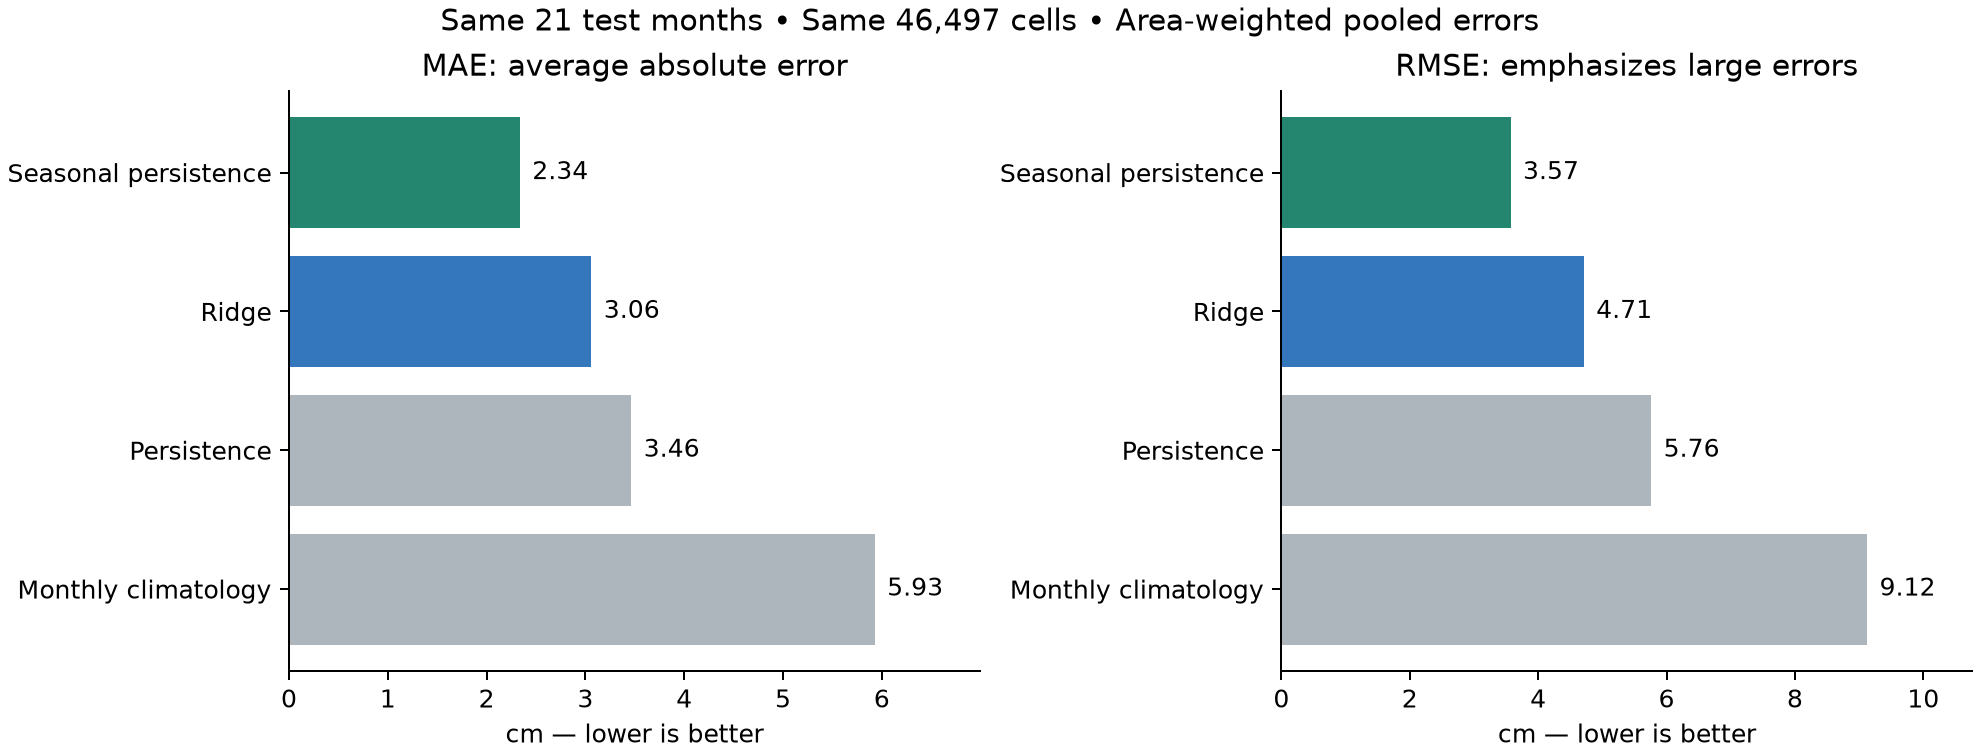

Lower error is better. Seasonal persistence is the strongest reference in this run.

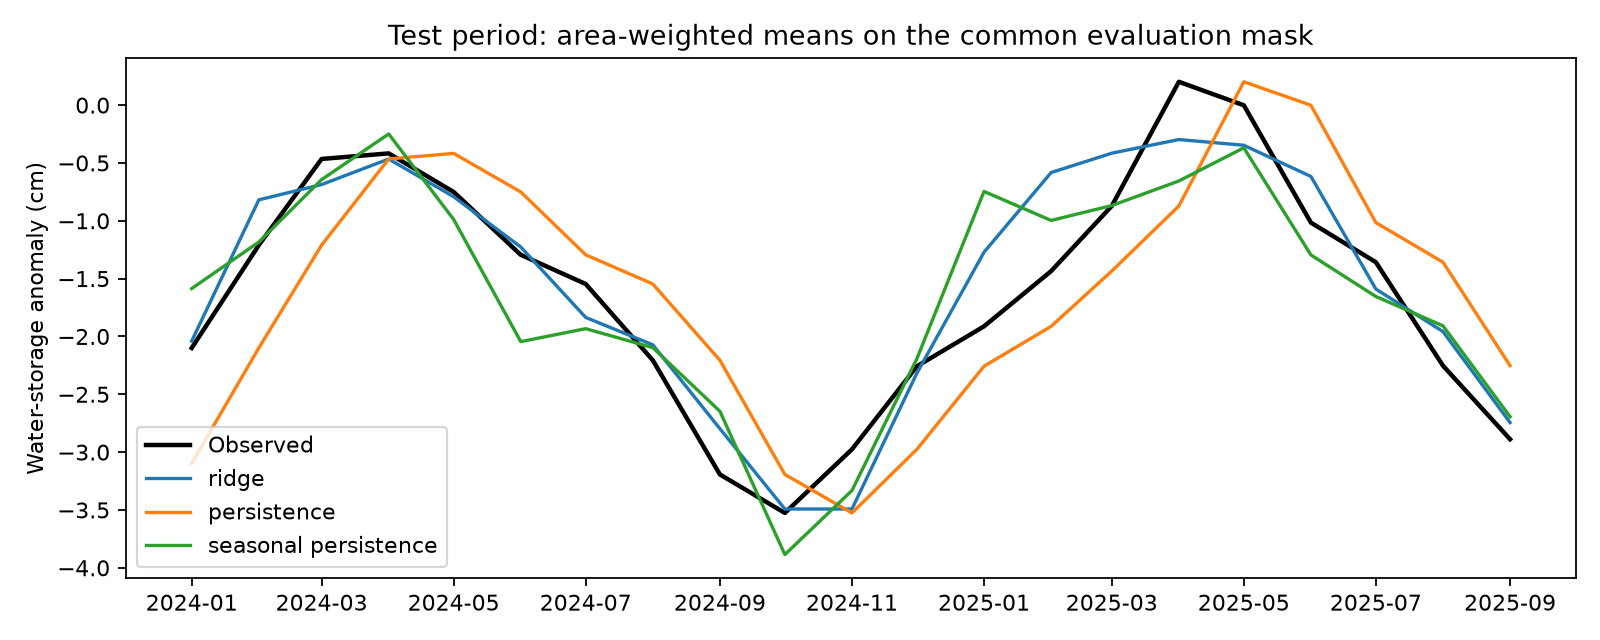

Area-average series help explain timing, but can hide local errors. The numeric scores use cell-month errors, not these averaged curves.

## 5. Training-period correlations
Pearson correlations are computed through time separately at each grid cell using training observations and then summarized with cosine-latitude weights. Seasonal anomalies are calculated by subtracting each cell's training-period calendar-month mean. Long-term trends are retained.

TWS has a weak positive mean correlation with precipitation and a negative mean correlation with temperature. The precipitation–temperature mean correlation changes from positive to negative after removal of the seasonal cycle, indicating that seasonal structure materially affects the aggregate association. Spatial averaging can conceal regional variation; these descriptive statistics establish neither causation nor statistical significance.

| relationship | period | eligible_cells | area_weighted_mean_r |
| --- | --- | --- | --- |
| raw_tws_precip | train | 46497 | 0.1833 |
| raw_tws_t2m | train | 46497 | -0.2553 |
| raw_precip_t2m | train | 46497 | 0.1231 |
| seasonal_anomaly_tws_precip | train | 46497 | 0.1521 |
| seasonal_anomaly_tws_t2m | train | 46497 | -0.2353 |
| seasonal_anomaly_precip_t2m | train | 46497 | -0.1937 |

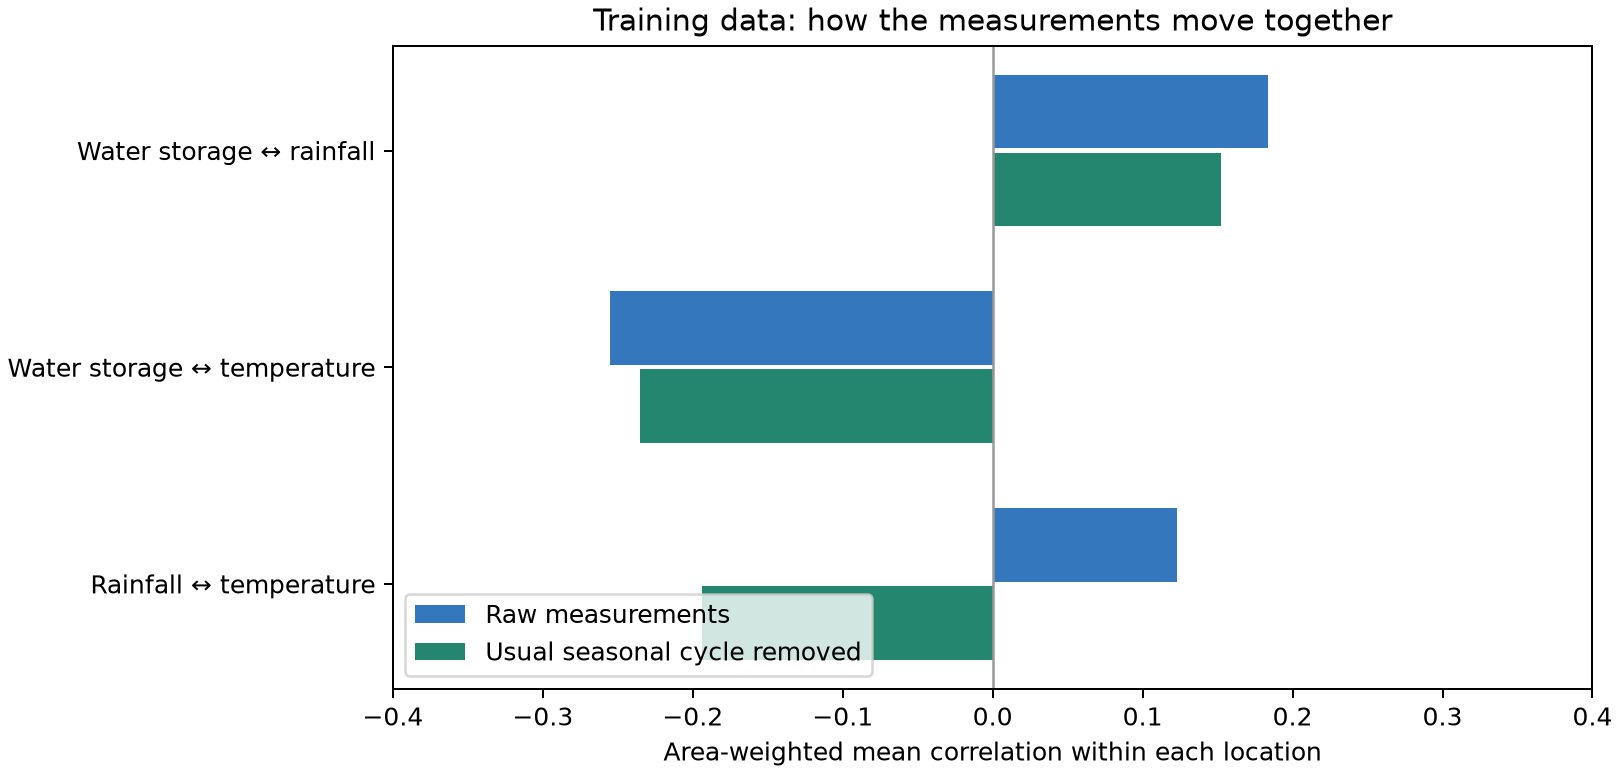

Seasonal adjustment changes the rainfall–temperature relationship from positive to negative on average.

## 6. Distribution analysis
Precipitation is right-skewed: its training-period area-weighted median is **36.78 mm/month**, compared with a mean of **74.59 mm/month**. The pooled TWS standard deviation increases from **18.98 cm** during training to **22.90 cm** during testing.

These differences describe the sampled distributions and do not establish a climate trend. The test interval contains January–September twice and October–December once, whereas the training interval contains complete calendar years. Consequently, raw split comparisons combine differences in seasonal composition with changes over time. Extreme observations are retained. The tabulated quantiles complement histograms whose full ranges and coarse bins may obscure central distribution differences.

| variable | split | observations | missing_fraction | area_weighted_mean | area_weighted_std | p05 | p25 | median | p75 | p95 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| tws | train | 2231856 | 0.0000 | -1.3843 | 18.9751 | -26.0022 | -8.3433 | -0.8553 | 6.1719 | 24.1393 |
| tws | validation | 557964 | 0.0000 | -1.7075 | 21.1634 | -27.3361 | -9.1090 | -0.8528 | 6.7879 | 25.3238 |
| tws | test | 976437 | 0.0000 | -1.5941 | 22.9013 | -29.9627 | -9.3155 | -0.6734 | 7.4621 | 27.9396 |
| precip | train | 2231856 | 0.0000 | 74.5909 | 96.9596 | 0.0288 | 7.2576 | 36.7776 | 103.7664 | 280.3690 |
| precip | validation | 557964 | 0.0000 | 70.4302 | 90.3363 | 0.0000 | 7.2317 | 35.6227 | 99.4752 | 256.3527 |
| precip | test | 976437 | 0.0000 | 75.2121 | 97.7189 | 0.0000 | 7.4400 | 37.6858 | 104.4576 | 278.0928 |
| t2m | train | 2231856 | 0.0000 | 16.9929 | 12.6417 | -9.6366 | 10.5062 | 21.0955 | 25.8981 | 31.3660 |
| t2m | validation | 557964 | 0.0000 | 17.5486 | 12.5967 | -8.9227 | 11.4030 | 21.5218 | 26.3686 | 31.8098 |
| t2m | test | 976437 | 0.0000 | 18.0235 | 12.4042 | -8.3588 | 11.8594 | 21.8506 | 26.7283 | 32.3106 |

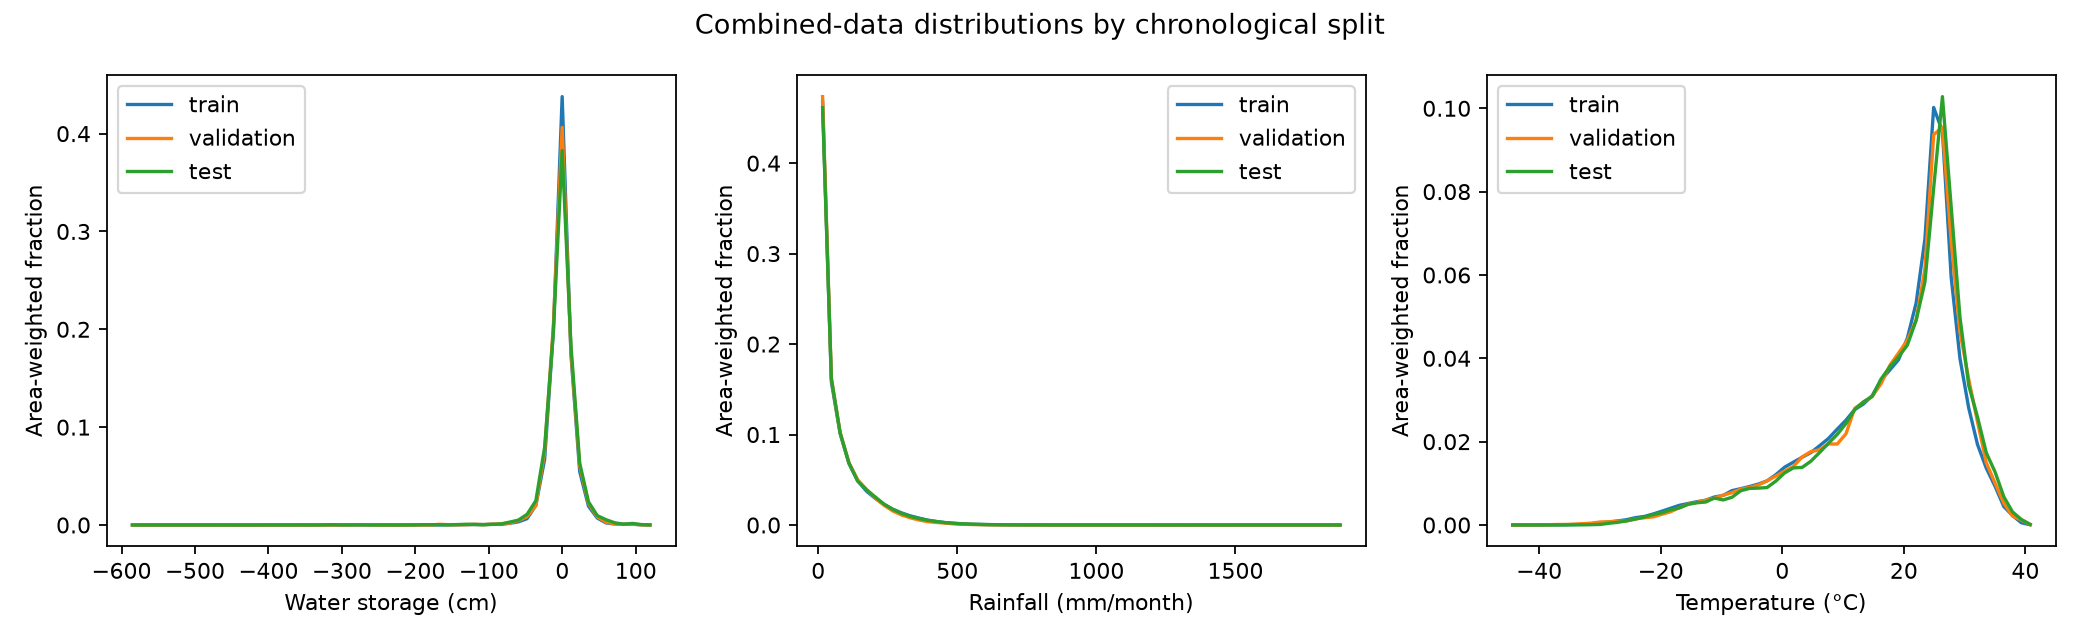

Area-weighted distributions across locations and months; training, validation, and testing are shown separately.

## 7. Sensitivity to RMSE aggregation
The primary metric pools weighted squared errors across cell-months before taking the square root. An alternative convention computes each cell's temporal RMSE first and then takes an area-weighted average:

$$\overline{\mathrm{RMSE}}=\frac{\sum_i w_i\sqrt{\frac{1}{n_i}\sum_t e_{it}^2}}{\sum_i w_i}.$$

These operations are not interchangeable. The alternative values below are included to support comparisons with analyses that use the per-cell convention. A comparison table must use a consistent aggregation method, test interval, mask, and predictor-availability assumption. Models using target-month climate observations address a different information setting from the lagged-input forecast evaluated here.

| model | area_weighted_mean_cell_rmse_cm |
| --- | --- |
| ridge | 3.6700 |
| persistence | 4.2279 |
| seasonal_persistence | 2.9421 |
| climatology | 6.7069 |

For the group comparison convention, `per_cell_test_metrics.csv` reports both MAE and RMSE as area-weighted means of temporal cell-level errors. The pipeline now exports this table directly. The saved-prediction scorer reproduces it from `test_predictions.nc`. Alpha selection retains the documented pooled validation criterion.

These results cover 21 months and 46,497 cells. The separate persistence results on main at commit `a388ee9` cover 24 months and 46,325 cells. A direct comparison therefore requires rescoring on the intersection of valid dates and cells, even when both analyses use 60°S–60°N latitude bounds.

## 8. Saved results and execution provenance
The embedded tables and figures summarize the completed script execution; the following inspection cell reads the saved metric table and run manifest. `ROOT` identifies the extracted package directory. The saved predictions, fitted parameters, split manifest, and verification records support independent inspection.

In [ ]:
from pathlib import Path
import json
import pandas as pd
ROOT = Path.cwd()
assert (ROOT / "test_metrics.csv").is_file(), "Set ROOT to the extracted contribution folder"
print(pd.read_csv(ROOT / "test_metrics.csv").to_string(index=False))
print(json.dumps(json.loads((ROOT / "run_manifest.json").read_text()), indent=2))

## 9. Reproduction procedure
The original `aligned_0.5deg.nc` dataset is required to reproduce the model run and is not duplicated in this package. Place it in the extracted package directory alongside this notebook. Its SHA-256 checksum is recorded in `run_manifest.json`.

The following cell verifies the input checksum and executes the analysis when `RUN_ANALYSIS` is enabled. Dependencies are listed in `requirements.txt`. New results are written to `rerun_results`; the archived results remain available without rerunning the analysis.

In [ ]:
import hashlib
import subprocess
import sys

INPUT = ROOT / "aligned_0.5deg.nc"
RUN_ANALYSIS = False

if RUN_ANALYSIS:
    if not INPUT.is_file():
        raise FileNotFoundError("Place aligned_0.5deg.nc beside this notebook before reproduction.")
    checksum = hashlib.sha256()
    with INPUT.open("rb") as source:
        for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
            checksum.update(block)
    manifest = json.loads((ROOT / "run_manifest.json").read_text())
    if checksum.hexdigest() != manifest["input_sha256"]:
        raise ValueError("Input checksum differs from the dataset used for the archived results.")
    subprocess.run([
        sys.executable, str(ROOT / "scripts" / "combined_ridge.py"),
        "--input", str(INPUT),
        "--config", str(ROOT / "configs" / "grace_fo_config.yaml"),
        "--output-dir", str(ROOT / "rerun_results"),
    ], check=True)
else:
    print("Archived results loaded; model reproduction is disabled.")

## 10. Verification, limitations, and conclusion
The pre-run regression suite passed 15 tests, including eight contribution-specific tests included in this package and seven existing repository tests. All four model metric sets were independently reproduced with the repository persistence evaluator. Archived coefficients and scalers reproduced forecasts at 12 distributed grid cells within float32 tolerance. All models used a common evaluation mask with finite predictions.

The 0.5° grid should not be interpreted as independent GRACE measurements at that spatial resolution. The retained-cell mask incorporates upstream full-record coverage, so spatial eligibility is not strictly prospective. The experiment does not evaluate generalization to unseen regions, uncertainty calibration, operational data latency, or the statistical significance of performance differences. Missing product release and acquisition metadata limit source provenance, although the input checksum identifies the exact analyzed file.

The combined-data analysis establishes distributional characteristics, seasonally adjusted associations, and a reproducible regularized linear baseline. Ridge improves upon ordinary persistence but does not surpass seasonal persistence in MAE or pooled RMSE. Subsequent experiments should preserve the common evaluation protocol, include the seasonal baseline, and use feature ablations to assess the additional value of precipitation and temperature.

The updated contribution suite passes 10 tests, including explicit latitude filtering and per-cell error aggregation with unequal observation counts. The archived model predictions are unchanged. Binary model and prediction files are provided in the complete analysis ZIP or regenerated by the reproduction command; they are excluded from the GitHub source contribution.